# Tools - Fractal dimension ($d_f$) of a network

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

## Computing fractal dimension - using MEMB
Use sequence of reduced graphs by applying Maximum Excluded Mass Burning (MEMB) algorithm (see notebook `F3-Reducing-graph-MEMB.ipynb`) with increasing radius.
Let 
- $N$ : number of graph nodes (in reduced graph)
- $\lambda$ : mean edge length (in reduced graph)

Then, one should have the relationship
- $N\propto \lambda^{-d_f}$

The fractal dimension $d_f$ is obtained by fitting a line on the log-log plot of $N$ as function of $\lambda$.

The dedicated function is `kn.tools.graph_fractal_dimension_with_memb`.

In [1]:
# import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
# import scipy
# import time


In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Illustration on a percolation cluster in 2D
A binary medium is generatated in a grid, where each cell is independently activated according to a site activation probability. Two activated cells that are adjacent in the grid is in the same connected component (or cluster). A connected component reaching two opposite borders of the grid in a finite grid or a connected component with an infinite number of sites in infinite grid, is said to be percolating.

The corresponding graph has the activated cells as nodes and the edges linking the adjacent nodes (adjacent activated cells in the grid).

The function `kn.misc.random_cluster_in_grid_2d` allows to generate such a graph.

### Percolation threshold
At a critical site activation probability, named **(site) percolation threshold**, noted $p_{critic}$ or $p_c$, the probability of percolation is equal to $0.5$ for finite grid, and the probability of percolation as function of the site activation probability $p$ is a step function going from $0$ to $1$ at the threshold $p=p_c$ for infinite grid.

The theoretical value (for large 2D grid) should be $p_{critic}\approx 0.592746$.

### Fractal dimension

The theoretical value for percolating cluster in (infinite) 2D grid is 
- $d_f = 91/48 \approx 1.896$

**Reference (see e.g.)**
- C. D. van Siclen (2021) *Conductivity exponents at the percolation threshold*, axrXiv (https://doi.org/10.48550/arXiv.1609.01229)


In [5]:
p_critic = 0.592746 # theoretical value of p_critic for infinite 2D grid

### Generate one percolation cluster

In [6]:
p = p_critic
mx, my = 251, 251
seed = 234

# Get list of graphs corresponding to the connected components
g_list = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)

# Get the largest connected component
g = g_list[0]

In [7]:
# Options for plot of 2D graph
options = {
    'node_size'   : 2,          # node size
    'node_color'  : 'tab:blue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',     # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,      # show node labels ?
    #
    # axes
    'show_ticks'  : True,       # show ticks ?
    'axis_equal'  : True        # aspect ratio equal ?
}

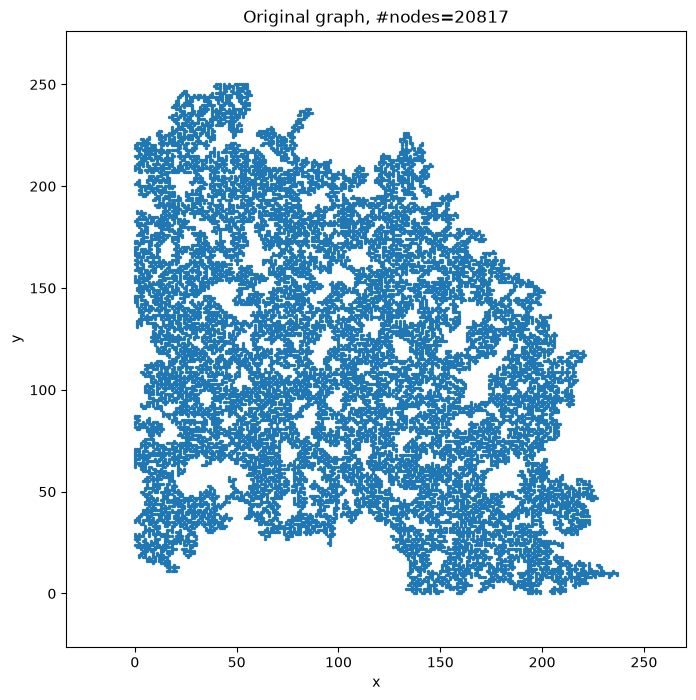

In [8]:
# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'Original graph, #nodes={g.number_of_nodes()}')
plt.show()

### Compute fractal dimension - using the dedicated function

Compute Reduced graphs (MEMB); original graph: #nodes = 20817, #edges = 26217; min #edges for red. graph: 524
MEMB, r = 1: #nodes = 7022, #edges = 8721, elapsed time : 41.49 sec
MEMB, r = 2: #nodes = 3882, #edges = 4664, elapsed time : 30.81 sec
MEMB, r = 3: #nodes = 2578, #edges = 3092, elapsed time : 27.12 sec
MEMB, r = 4: #nodes = 1859, #edges = 2218, elapsed time : 24.70 sec
MEMB, r = 5: #nodes = 1444, #edges = 1731, elapsed time : 23.73 sec
MEMB, r = 6: #nodes = 1161, #edges = 1396, elapsed time : 23.30 sec
MEMB, r = 7: #nodes = 952, #edges = 1116, elapsed time : 21.74 sec
MEMB, r = 8: #nodes = 804, #edges = 938, elapsed time : 21.12 sec
MEMB, r = 9: #nodes = 709, #edges = 844, elapsed time : 21.14 sec
MEMB, r = 10: #nodes = 609, #edges = 721, elapsed time : 20.63 sec
MEMB, r = 11: #nodes = 540, #edges = 637, elapsed time : 20.65 sec
MEMB, r = 12: #nodes = 479, #edges = 556, elapsed time : 20.53 sec
MEMB, r = 13: #nodes = 437, #edges = 508, elapsed time : 20.99 sec
Stop MEMB (#edg

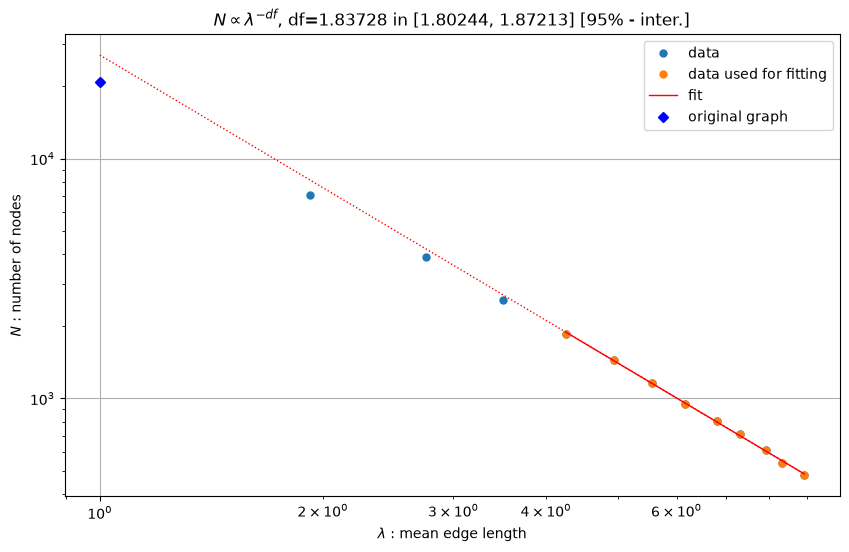

In [9]:
# Set figure (next computation makes a plot)
plt.figure(figsize=(10, 6))

# Compute fractal dimension (- and make plot)
# - parameters for fitting line on log-log plot
min_n_edges_fraction = 0.02 # stop MEMB reduction if number of edges in reduced graph is below
min_n_edges_lim      = 3    # `min_n_edges_fraction` times the number of edges in original graph 
                            # or below min_n_edges_lim    
data_points_removed_first_fraction = 0.33 # part of the points removed from the beginning to do the fit
data_points_removed_last_fraction  = 0.0  # part of the points removed from the end to do the fit
confidence_level = 0.95     # confidence level for fitting

out_dict = kn.tools.graph_fractal_dimension_with_memb(
            g,
            r_values=np.arange(1, 101),
            min_n_edges_fraction=min_n_edges_fraction,
            min_n_edges_lim=min_n_edges_lim,
            data_points_removed_first_fraction=data_points_removed_first_fraction,
            data_points_removed_last_fraction=data_points_removed_last_fraction,
            confidence_level=confidence_level,
            pos_attr='pos',
            memb_edge_weight=None,
            memb_node_attr_mode='mean',
            memb_node_attr_list=None,
            memb_node_group_id_dict=None,
            return_poly_fit_params=True,
            return_poly_fit_params_cov=True,
            return_index_used_for_fit=True,
            return_G_red_mean_edge_length_list=True,
            return_G_red_n_nodes_list=True,
            return_G_red_n_edges_list=True,
            return_G_red_r_list=True,
            return_G_red_list=True,
            seed=98274,
            verbose=1,
            make_plot=True,
            plot_in_log_scale=True)

# Show plot
plt.show()

In [10]:
# Show output dictionary (keys and type of values)
for k, v in out_dict.items():
    print(f'key = {k:30s}: value type {type(v)}')

key = df                            : value type <class 'numpy.float64'>
key = df_delta                      : value type <class 'numpy.float64'>
key = confidence_level              : value type <class 'float'>
key = poly_fit_params               : value type <class 'numpy.ndarray'>
key = poly_fit_params_cov           : value type <class 'numpy.ndarray'>
key = index_used_for_fit            : value type <class 'list'>
key = G_red_mean_edge_length_list   : value type <class 'list'>
key = G_mean_edge_length            : value type <class 'float'>
key = G_red_n_nodes_list            : value type <class 'list'>
key = G_n_nodes                     : value type <class 'int'>
key = G_red_n_edges_list            : value type <class 'list'>
key = G_n_edges                     : value type <class 'int'>
key = G_red_r_list                  : value type <class 'list'>
key = G_red_list                    : value type <class 'list'>


In [11]:
# Get result from the output dictionary
# - fractal dimension
df = out_dict['df']
df_delta = out_dict['df_delta']
confidence_level = out_dict['confidence_level']

# - reduced graphs
g_red_list                  = out_dict['G_red_list']
# - corresponding r values, mean edge length, etc.
g_red_r_list                = out_dict['G_red_r_list']
g_red_n_nodes_list          = out_dict['G_red_n_nodes_list']
g_red_n_edges_list          = out_dict['G_red_n_edges_list']
g_red_mean_edge_length_list = out_dict['G_red_mean_edge_length_list']

# - parameters of the fitted polynom (line in log-log scale)
poly_fit_params     = out_dict['poly_fit_params']
poly_fit_params_cov = out_dict['poly_fit_params_cov']
# - starting and ending indices of data points sequence used for fitting
index_used_for_fit = out_dict['index_used_for_fit']

In [12]:
# Print fractal dimension
df_lim_min, df_lim_max = df - df_delta, df + df_delta
print(f'Fractal dimension = {df:.5f} in [{df_lim_min:.5f}, {df_lim_max:.5f}] [{100*confidence_level:.2g}% - inter.]')

Fractal dimension = 1.83728 in [1.80244, 1.87213] [95% - inter.]


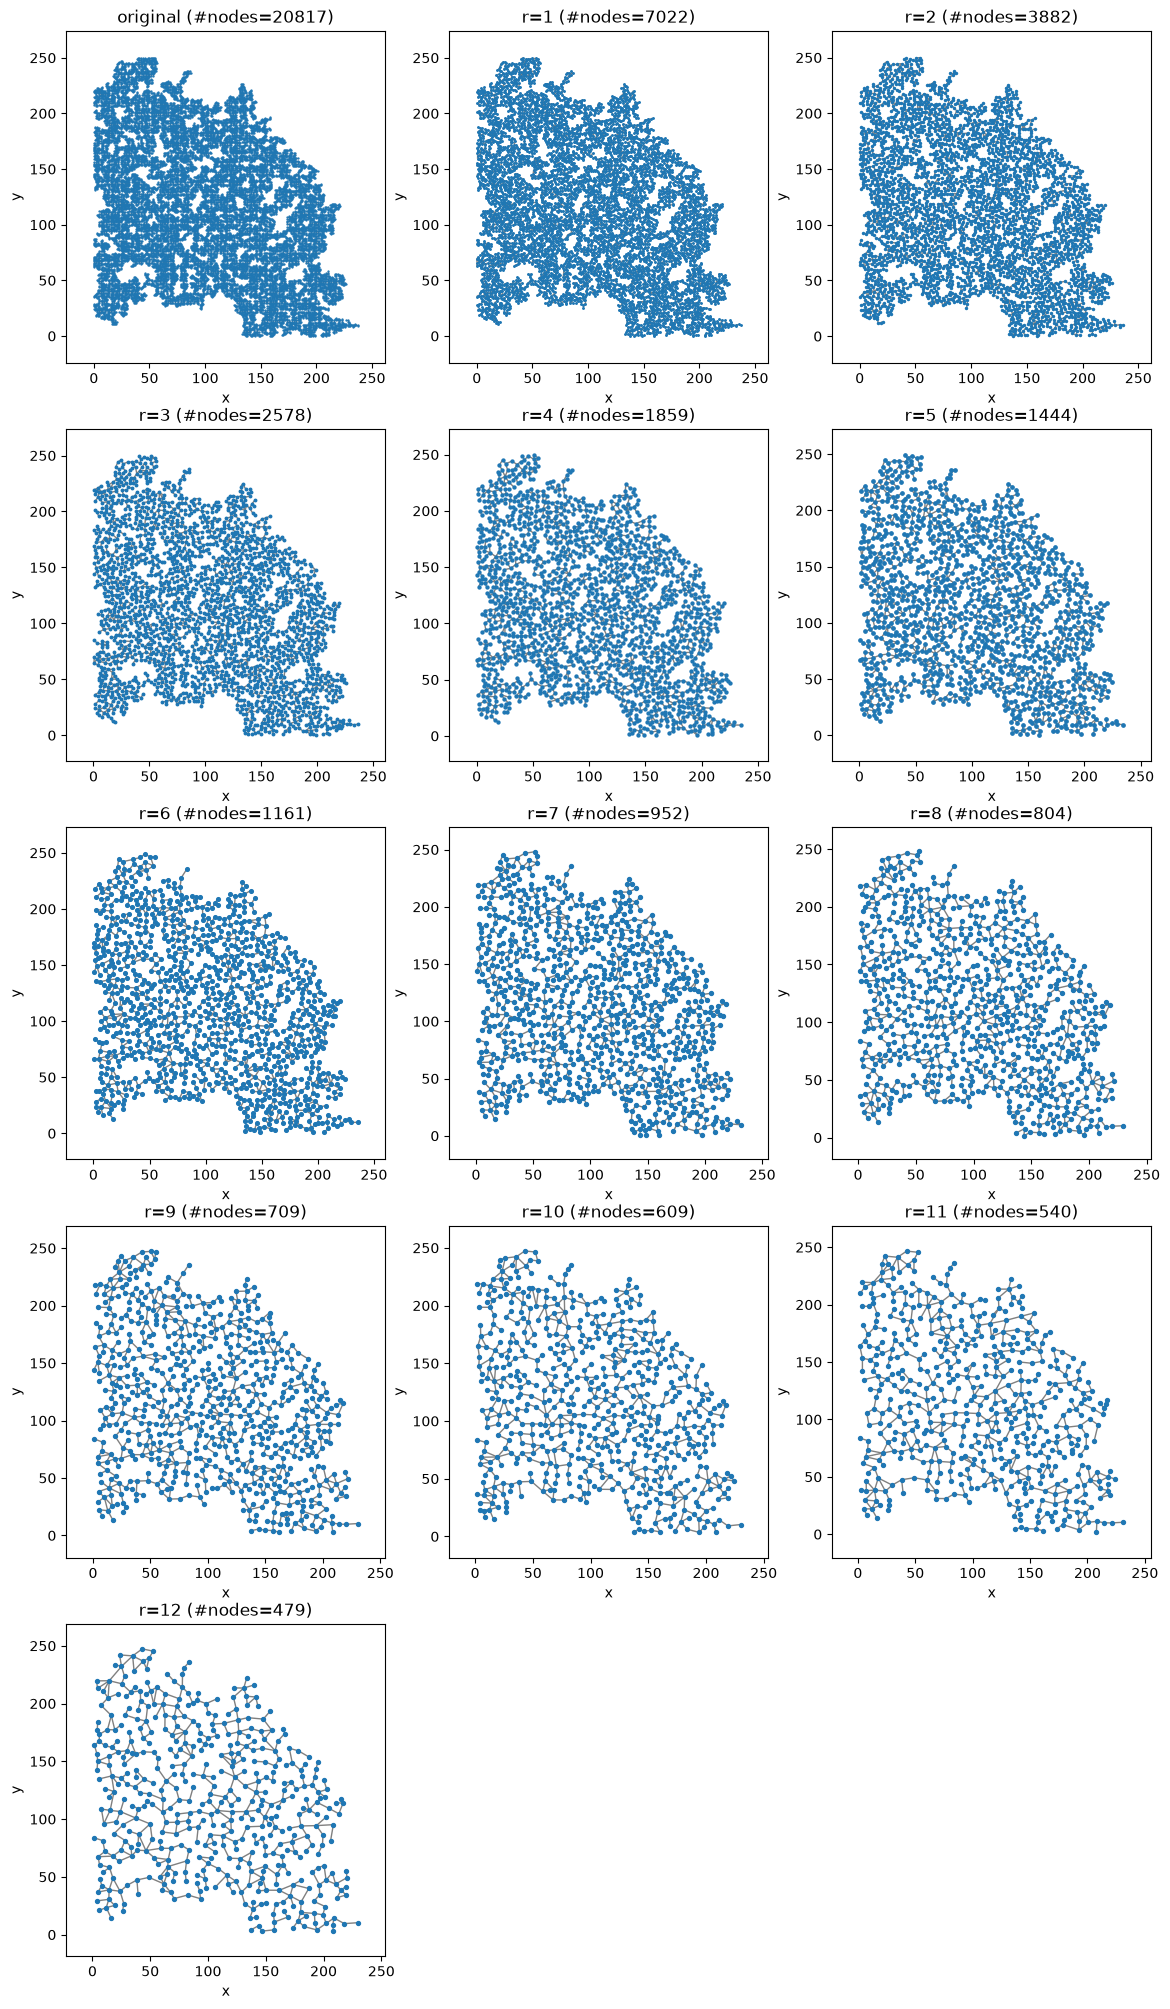

In [13]:
# Plot list of graphs - original graph reduced graphs
options = {
    'node_size'   : 1,          # node size
    'node_color'  : 'tab:blue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',     # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,      # show node labels ?
    #
    # axes
    'show_ticks'  : True,       # show ticks ?
    'axis_equal'  : True        # aspect ratio equal ?
}

# Select index of reduced graphs to be plotted
ind_selected = np.arange(0, len(g_red_list))

g_n_nodes = g.number_of_nodes()

g_list = [g] + [g_red_list[i] for i in ind_selected]
name_list = [f'original (#nodes={g_n_nodes})'] + [f'r={g_red_r_list[i]:.3g} (#nodes={g_red_n_nodes_list[i]})' for i in ind_selected]

nn = len(g_list)
nc = min(3, nn)
nr = nn//nc + int(nn%nc > 0)

plt.subplots(nr, nc, figsize=(14, nr*5)) #, sharex=True, sharey=True) # cannot share axis with aspect 'equal'

for i, (gi, name) in enumerate(zip(g_list, name_list)):
    options['node_size'] = 0.4*min(g_n_nodes/gi.number_of_nodes(), 20) # adapt node size
    plt.subplot(nr, nc, i+1)
    kn.view.plot_graph2d(gi, **options)
    plt.title(name)

for i in range(nn, nr*nc):
    plt.subplot(nr, nc, i+1)
    plt.axis('off')

plt.show()


### Adapt the fit of the line on the log-log plot (if needed)
The function `kn.tools.graph_fractal_dimension_with_memb_update` allows to update the computation of the fractal dimension (without re-computing the reduced graphs) by adapting the points used for fitting the line on the log-log plot by changing the parameters `data_points_removed_first_fraction`, `data_points_removed_last_fraction` (and `confidence_interval`). 

Note that using the same parameters gives the same results and allows to re-do the plot of the fit. Alternatively, the function `kn.tools.plot_fit_fractal_dimension` can be used to re-do the plot.

Compute fractal dimension (line fitting on log-log plot of number of nodes as function of mean edge length)
Fitting on 7 points (over 13)


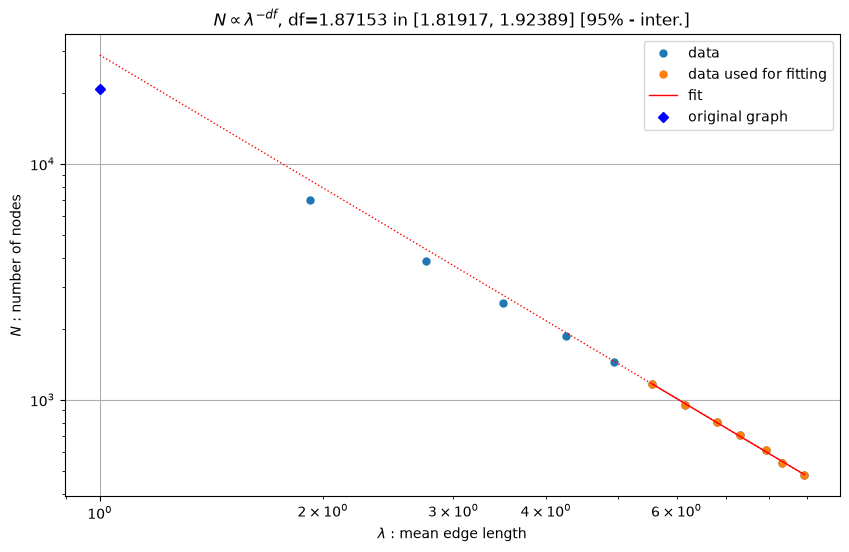

In [19]:
# out_dict_save = out_dict.copy() # save a copy of the results (if wanted)

# Set figure (next computation makes a plot)
plt.figure(figsize=(10, 6))

out_dict = kn.tools.graph_fractal_dimension_with_memb_update(
        out_dict,
        data_points_removed_first_fraction=0.5,
        data_points_removed_last_fraction=0.0,
        confidence_level=0.95,
        verbose=1,
        make_plot=True,
        plot_in_log_scale=True)

# Show plot
plt.show()

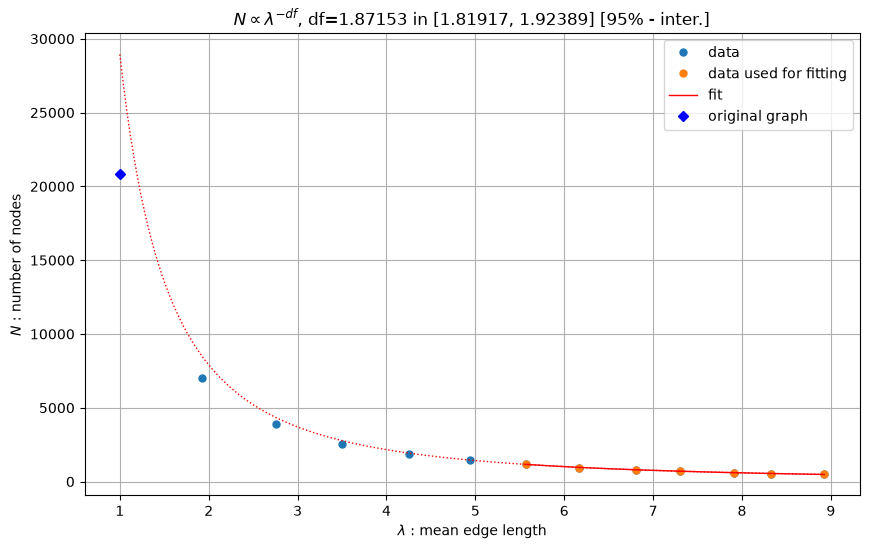

In [20]:
# Re-do the plot (not in log-log scale)

# Set figure
plt.figure(figsize=(10, 6))

x_all = np.asarray([out_dict['G_mean_edge_length']] + out_dict['G_red_mean_edge_length_list'])
y_all = np.asarray([out_dict['G_n_nodes']] + out_dict['G_red_n_nodes_list'])
n1, n2 = out_dict['index_used_for_fit']
x = x_all[n1:n2]
y = y_all[n1:n2]
x0 = out_dict['G_mean_edge_length']
y0 = out_dict['G_n_nodes']
df = out_dict['df']
df_delta = out_dict['df_delta']
confidence_level = out_dict['confidence_level']
poly_fit_params = out_dict['poly_fit_params']

kn.tools.plot_fit_fractal_dimension(
    x_all, y_all, x, y, x0, y0, 
    df, df_delta, confidence_level, poly_fit_params, 
    plot_fit=True, plot_in_log_scale=False)

# Show plot
plt.show()